# 03 · Evaluate the Models and Select the Best
**RedactNER: Local PII Redaction for Word Documents**

This notebook compares the three fine-tuned encoders (DeBERTa-v3-base as the main model, with
RoBERTa-base and ModernBERT-base as baselines) and a rule-based reference on three test sets.

| Test Set | Purpose |
|---|---|
| Nemotron-PII | In-domain, document-style synthetic PII |
| ai4privacy OpenPII | In-domain, short synthetic texts |
| Gretel Finance | Long financial documents from a generator never seen during training |

All metrics are computed on character spans, so they do not depend on any tokenizer.
* **Character-Level Precision, Recall, F1 and F5.** Label-agnostic scores that measure whether the right
  text was redacted. F5 weights recall five times as heavily as precision, because a missed identifier is
  a privacy breach while an extra redaction only reduces readability.
* **Leak Rate.** The share of gold mentions with at least one alphanumeric character left visible.
* **Entity Precision, Recall and F1.** Typed, strict scores that require exact boundaries and the correct
  category, the standard view for named entity recognition.

The decision threshold τ (a token is tagged as PII when P(O) < τ) is tuned on the development set for
each model. The best model is selected on the development set before the test sets are scored, and it is
then evaluated inside the full hybrid pipeline with validated rules and document-wide propagation.

In [1]:
RUNS = ["roberta-base", "modernbert-base", "deberta-v3-base"]
MAIN = "deberta-v3-base"
TEST_SETS = ["test_nemotron", "test_ai4privacy", "test_gretel"]
TAU_GRID = [0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95, 0.97, 0.99]
MIN_PRECISION = 0.80   # minimum character-level precision for the recall-oriented operating point
MAX_DOCS = None        # optional cap on documents per set (None uses all)
PROJECT_DIR = ".."

## 0. Setup
This notebook uses the project package in `src/redactner`. On Google Colab, clone the repository and run
`pip install -e .` first.

In [2]:
import json
import shutil
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from transformers import AutoModelForTokenClassification, AutoTokenizer

ROOT = Path(PROJECT_DIR).resolve()
sys.path.insert(0, str(ROOT / "src"))
from redactner.fusion import HybridDetector  # noqa: E402
from redactner.inference import META_FILE, TokenClassifierDetector  # noqa: E402
from redactner.labels import LABELS  # noqa: E402
from redactner.metrics import CorpusScorer  # noqa: E402
from redactner.rules import RuleDetector  # noqa: E402

DATA = ROOT / "data" / "processed"
MODELS = ROOT / "models"
RESULTS = ROOT / "results" / "prototype"
RESULTS.mkdir(parents=True, exist_ok=True)
print("CUDA available:", torch.cuda.is_available())

MODEL_NAMES = {"roberta-base": "RoBERTa-base", "modernbert-base": "ModernBERT-base",
               "deberta-v3-base": "DeBERTa-v3-base"}
SET_NAMES = {"dev": "Development", "test_nemotron": "Nemotron-PII", "test_ai4privacy": "ai4privacy OpenPII",
             "test_gretel": "Gretel Finance"}
CATEGORY_NAMES = {"PERSON": "Person", "EMAIL": "Email", "PHONE": "Phone", "ADDRESS": "Address",
                  "LOCATION": "Location", "DATE": "Date", "ID_NUMBER": "ID Number", "FINANCIAL": "Financial",
                  "USERNAME": "Username", "CREDENTIAL": "Credential", "IP_ADDRESS": "IP Address", "URL": "URL",
                  "ORGANIZATION": "Organisation"}
METRIC_NAMES = {"tau": "τ", "char_precision": "Char Precision", "char_recall": "Char Recall",
                "char_f1": "Char F1", "char_f5": "Char F5", "leak_rate": "Leak Rate",
                "entity_precision": "Entity Precision", "entity_recall": "Entity Recall", "entity_f1": "Entity F1"}


def model_name(run):
    return MODEL_NAMES.get(run, run)


def read_jsonl(path):
    with open(path, encoding="utf-8") as fh:
        docs = [json.loads(line) for line in fh]
    return docs[:MAX_DOCS] if MAX_DOCS else docs


sets = {name: read_jsonl(DATA / f"{name}.jsonl") for name in ["dev"] + TEST_SETS}
print("Documents per set:", ", ".join(f"{SET_NAMES[k]} {len(v):,}" for k, v in sets.items()))

CUDA available: True
Documents per set: Development 1,500, Nemotron-PII 1,000, ai4privacy OpenPII 999, Gretel Finance 500


## 1. Token Probabilities
Token probabilities are computed once for every model and data set, then decoded under different
thresholds.

In [3]:
detectors, probs, latency = {}, {}, {}
for run in RUNS:
    det = TokenClassifierDetector(MODELS / run)
    detectors[run] = det
    for name, docs in sets.items():
        t0 = time.perf_counter()
        probs[(run, name)] = [det.token_probs(d["text"]) for d in docs]
        elapsed = time.perf_counter() - t0
        if name == "test_nemotron":
            n_chars = sum(len(d["text"]) for d in docs)
            latency[run] = {"ms_per_doc": 1000 * elapsed / len(docs), "ms_per_1k_chars": 1e6 * elapsed / n_chars}
        print(f"{model_name(run):<17} {SET_NAMES[name]:<20} {elapsed:6.1f} s")
    torch.cuda.empty_cache()


def score(docs, preds):
    sc = CorpusScorer(LABELS)
    for d, p in zip(docs, preds):
        sc.add(d["text"], d["spans"], [(s.start, s.end, s.label) for s in p])
    return sc


def decode_all(run, name, tau=None, argmax=False):
    det = detectors[run]
    det.decoding = "argmax" if argmax else "threshold"
    out = [det.decode(d["text"], tp, tau) for d, tp in zip(sets[name], probs[(run, name)])]
    det.decoding = "threshold"
    return out

RoBERTa-base      Development            13.1 s


RoBERTa-base      Nemotron-PII            9.0 s


RoBERTa-base      ai4privacy OpenPII      7.7 s


RoBERTa-base      Gretel Finance          4.9 s


ModernBERT-base   Development            29.4 s


...

ModernBERT-base   Gretel Finance          9.7 s


DeBERTa-v3-base   Development            85.3 s


DeBERTa-v3-base   Nemotron-PII           26.6 s


DeBERTa-v3-base   ai4privacy OpenPII     20.1 s


DeBERTa-v3-base   Gretel Finance         11.1 s


## 2. Threshold Tuning on the Development Set
Each model receives its own operating point: the threshold with the highest character-level F5, subject
to a minimum character-level precision of 0.80.

In [4]:
sweep_rows = []
for run in RUNS:
    for tau in TAU_GRID:
        s = score(sets["dev"], decode_all(run, "dev", tau)).summary()
        sweep_rows.append({"run": run, "tau": tau, **{k: s[k] for k in
                           ("char_precision", "char_recall", "char_f1", "char_f5", "entity_f1", "leak_rate")}})
sweep = pd.DataFrame(sweep_rows)


def pick_tau(df):
    ok = df[df.char_precision >= MIN_PRECISION]
    best = (ok if len(ok) else df).sort_values(["char_f5", "entity_f1"], ascending=False).iloc[0]
    return float(best.tau)


def pretty(df):
    """Display copy of a metrics table with readable model and column names."""
    out = df.rename(columns=METRIC_NAMES)
    out.index = [model_name(i) for i in out.index]
    out.index.name = "Model"
    return out


chosen_tau = {run: pick_tau(sweep[sweep.run == run]) for run in RUNS}
dev_best = sweep[[chosen_tau[r] == t for r, t in zip(sweep.run, sweep.tau)]].set_index("run")
print("Chosen τ per model:", ", ".join(f"{model_name(r)} {t}" for r, t in chosen_tau.items()))
pretty(dev_best.round(4))

Chosen τ per model: RoBERTa-base 0.97, ModernBERT-base 0.99, DeBERTa-v3-base 0.9


,τ,Char Precision,Char Recall,Char F1,Char F5,Entity F1,Leak Rate
Model,,,,,,,
RoBERTa-base,0.97,0.9647,0.9984,0.9813,0.9970,0.9601,0.0023
ModernBERT-base,0.99,0.9530,0.9990,0.9755,0.9972,0.9383,0.0018
DeBERTa-v3-base,0.90,0.9812,0.9966,0.9889,0.9960,0.9730,0.0036


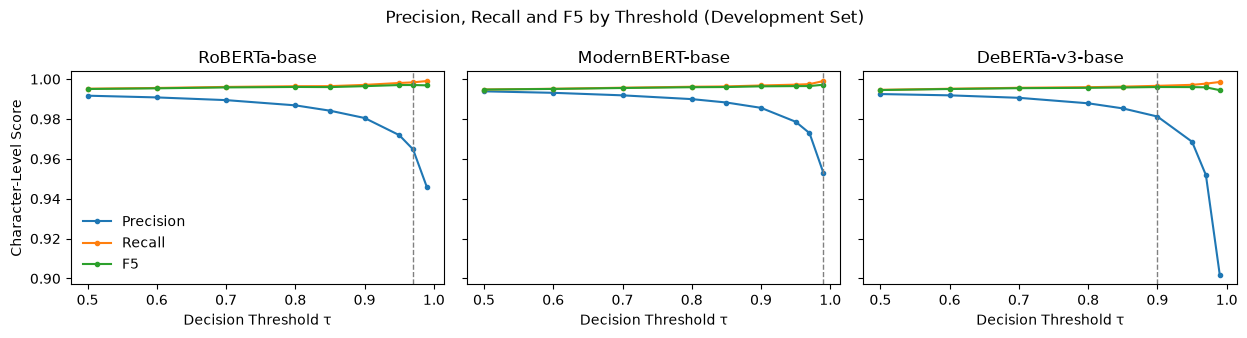

In [5]:
fig, axes = plt.subplots(1, len(RUNS), figsize=(4.2 * len(RUNS), 3.4), sharey=True)
for ax, run in zip(np.atleast_1d(axes), RUNS):
    d = sweep[sweep.run == run]
    for col, lab in (("char_precision", "Precision"), ("char_recall", "Recall"), ("char_f5", "F5")):
        ax.plot(d.tau, d[col], "o-", label=lab, markersize=3)
    ax.axvline(chosen_tau[run], color="grey", linestyle="--", linewidth=1)
    ax.set_title(model_name(run))
    ax.set_xlabel("Decision Threshold τ")
axes[0].set_ylabel("Character-Level Score")
axes[0].legend(frameon=False)
fig.suptitle("Precision, Recall and F5 by Threshold (Development Set)")
plt.tight_layout()
plt.savefig(RESULTS / "fig_threshold_sweep.png", dpi=150)
plt.show()

## 3. Model Selection
The model with the highest development F5 at its tuned threshold is selected, with strict entity F1 as the
tie-breaker.

In [6]:
ranking = dev_best.sort_values(["char_f5", "entity_f1"], ascending=False)
BEST = ranking.index[0]
print(f"Selected model: {model_name(BEST)} (τ = {chosen_tau[BEST]})")
selection_cols = ["tau", "char_precision", "char_recall", "char_f5", "entity_f1", "leak_rate"]
pretty(ranking[selection_cols].round(4))

Selected model: ModernBERT-base (τ = 0.99)


,τ,Char Precision,Char Recall,Char F5,Entity F1,Leak Rate
Model,,,,,,
ModernBERT-base,0.99,0.9530,0.9990,0.9972,0.9383,0.0018
RoBERTa-base,0.97,0.9647,0.9984,0.9970,0.9601,0.0023
DeBERTa-v3-base,0.90,0.9812,0.9966,0.9960,0.9730,0.0036


## 4. Test Results
Each test set is scored for rule-based detection only, for every model with argmax decoding and at its
tuned threshold, and for the selected model inside the full hybrid pipeline with validated rules and
document-wide propagation.

In [7]:
rules = RuleDetector()
hybrid = HybridDetector(detectors[BEST], rules, use_rules=True, use_propagation=True)
HYBRID_NAME = f"RedactNER Hybrid ({model_name(BEST)})"
rows, per_label = [], {}
for name in TEST_SETS:
    docs = sets[name]
    systems = {"Rules Only": [rules.detect(d["text"]) for d in docs]}
    for run in RUNS:
        systems[f"{model_name(run)} (Argmax)"] = decode_all(run, name, argmax=True)
        systems[f"{model_name(run)} (τ = {chosen_tau[run]})"] = decode_all(run, name, chosen_tau[run])
    systems[HYBRID_NAME] = [hybrid.detect(d["text"], threshold=chosen_tau[BEST]) for d in docs]
    for sys_name, preds in systems.items():
        sc = score(docs, preds)
        rows.append({"test_set": name, "system": sys_name, **sc.summary()})
        per_label[(name, sys_name)] = sc.per_label()

results = pd.DataFrame(rows)
cols = ["char_precision", "char_recall", "char_f1", "char_f5", "leak_rate", "entity_precision", "entity_recall",
        "entity_f1"]


def test_table(name):
    table = results[results.test_set == name].set_index("system")[cols].round(4).rename(columns=METRIC_NAMES)
    table.index.name = "System"
    return table


for name in TEST_SETS:
    print(f"\n{SET_NAMES[name]} Test Set")
    display(test_table(name))  # noqa: F821


Nemotron-PII Test Set


,Char Precision,Char Recall,Char F1,Char F5,Leak Rate,Entity Precision,Entity Recall,Entity F1
System,,,,,,,,
Rules Only,0.9925,0.3879,0.5578,0.3972,0.7758,0.9060,0.2148,0.3473
RoBERTa-base (Argmax),0.9906,0.9891,0.9898,0.9891,0.0137,0.9748,0.9774,0.9761
RoBERTa-base (τ = 0.97),0.9469,0.9952,0.9705,0.9933,0.0062,0.9171,0.9816,0.9483
ModernBERT-base (Argmax),0.9918,0.9873,0.9895,0.9874,0.0196,0.9665,0.9702,0.9683
ModernBERT-base (τ = 0.99),0.9373,0.9957,0.9656,0.9933,0.0055,0.8727,0.9777,0.9222
DeBERTa-v3-base (Argmax),0.9903,0.9885,0.9894,0.9886,0.0148,0.9768,0.9786,0.9777
DeBERTa-v3-base (τ = 0.9),0.9768,0.9927,0.9847,0.9921,0.0078,0.9501,0.9825,0.9660
RedactNER Hybrid (ModernBERT-base),0.9370,0.9961,0.9656,0.9937,0.0047,0.8754,0.9613,0.9163



ai4privacy OpenPII Test Set


,Char Precision,Char Recall,Char F1,Char F5,Leak Rate,Entity Precision,Entity Recall,Entity F1
System,,,,,,,,
Rules Only,0.9968,0.1438,0.2514,0.1487,0.8584,0.9191,0.1325,0.2316
RoBERTa-base (Argmax),0.9965,0.9985,0.9975,0.9984,0.0039,0.9865,0.9882,0.9873
RoBERTa-base (τ = 0.97),0.9916,0.9997,0.9956,0.9994,0.0013,0.9766,0.9898,0.9832
ModernBERT-base (Argmax),0.9962,0.9980,0.9971,0.9979,0.0044,0.9841,0.9882,0.9861
ModernBERT-base (τ = 0.99),0.9894,0.9997,0.9945,0.9993,0.0009,0.9665,0.9883,0.9773
DeBERTa-v3-base (Argmax),0.9973,0.9980,0.9976,0.9979,0.0052,0.9902,0.9913,0.9908
DeBERTa-v3-base (τ = 0.9),0.9946,0.9991,0.9969,0.9990,0.0026,0.9857,0.9924,0.9890
RedactNER Hybrid (ModernBERT-base),0.9887,0.9999,0.9942,0.9994,0.0004,0.9629,0.9808,0.9718



Gretel Finance Test Set


,Char Precision,Char Recall,Char F1,Char F5,Leak Rate,Entity Precision,Entity Recall,Entity F1
System,,,,,,,,
Rules Only,0.3462,0.0877,0.1399,0.0903,0.9374,0.3943,0.0602,0.1045
RoBERTa-base (Argmax),0.6757,0.7256,0.6998,0.7235,0.3585,0.4066,0.5217,0.4570
RoBERTa-base (τ = 0.97),0.5817,0.8114,0.6776,0.7993,0.2713,0.3240,0.5813,0.4160
ModernBERT-base (Argmax),0.6945,0.7220,0.7080,0.7209,0.3847,0.3540,0.4806,0.4077
ModernBERT-base (τ = 0.99),0.5328,0.8295,0.6488,0.8121,0.2551,0.2250,0.5634,0.3216
DeBERTa-v3-base (Argmax),0.6309,0.7240,0.6742,0.7199,0.3814,0.3225,0.4904,0.3891
DeBERTa-v3-base (τ = 0.9),0.5605,0.7907,0.6560,0.7784,0.2922,0.3066,0.5665,0.3979
RedactNER Hybrid (ModernBERT-base),0.5181,0.8320,0.6385,0.8131,0.2430,0.2663,0.5995,0.3688


### Strict Entity F1 by Category
Results for the three models at their tuned thresholds on the in-domain document test set.

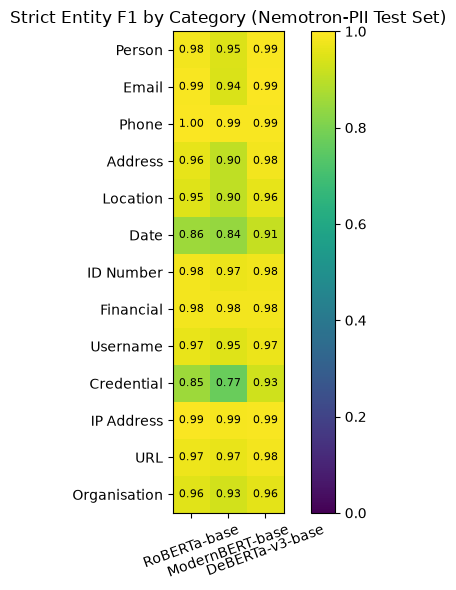

,RoBERTa-base,ModernBERT-base,DeBERTa-v3-base
Person,0.983,0.949,0.990
Email,0.990,0.942,0.993
Phone,0.995,0.989,0.991
Address,0.963,0.903,0.984
Location,0.950,0.905,0.963
Date,0.855,0.843,0.913
ID Number,0.981,0.969,0.978
Financial,0.982,0.984,0.981
Username,0.966,0.949,0.971
Credential,0.855,0.770,0.928


In [8]:
heat = pd.DataFrame({model_name(run): {CATEGORY_NAMES[lab]: per_label[("test_nemotron", f"{model_name(run)} (τ = {chosen_tau[run]})")][lab]["f1"]
                                       for lab in LABELS} for run in RUNS})
fig, ax = plt.subplots(figsize=(6, 6))
im = ax.imshow(heat.values, cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(len(RUNS)), list(heat.columns), rotation=20)
ax.set_yticks(range(len(LABELS)), list(heat.index))
for i in range(len(LABELS)):
    for j in range(len(RUNS)):
        ax.text(j, i, f"{heat.values[i, j]:.2f}", ha="center", va="center",
                color="white" if heat.values[i, j] < 0.6 else "black", fontsize=8)
ax.set_title("Strict Entity F1 by Category (Nemotron-PII Test Set)")
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.savefig(RESULTS / "fig_per_type_f1.png", dpi=150)
plt.show()
heat.round(3)

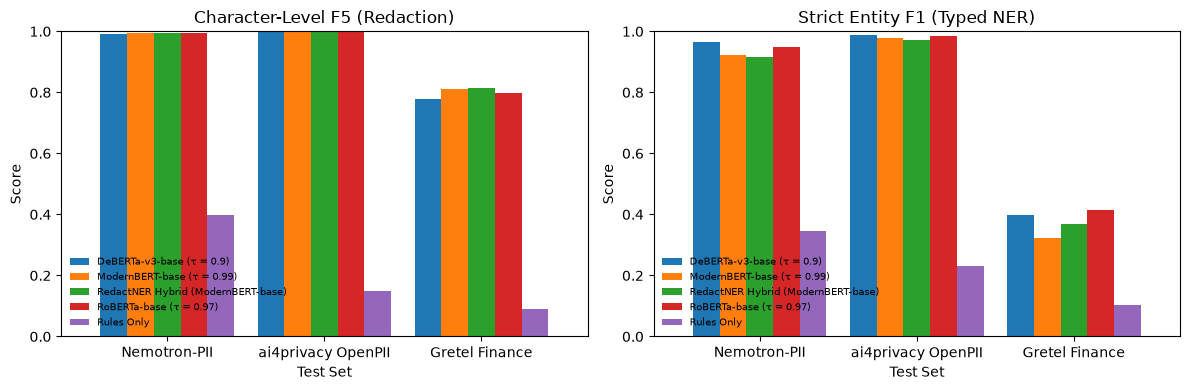

,Milliseconds per Document,"Milliseconds per 1,000 Characters"
Model,,
RoBERTa-base,9.0,9.5
ModernBERT-base,19.5,20.6
DeBERTa-v3-base,26.6,28.0


In [9]:
plot_df = results[results.system.str.contains("τ =") | results.system.isin(["Rules Only", HYBRID_NAME])].copy()
plot_df["Test Set"] = plot_df.test_set.map(SET_NAMES)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, title in ((axes[0], "char_f5", "Character-Level F5 (Redaction)"),
                          (axes[1], "entity_f1", "Strict Entity F1 (Typed NER)")):
    piv = plot_df.pivot(index="Test Set", columns="system", values=metric).loc[[SET_NAMES[n] for n in TEST_SETS]]
    piv.plot.bar(ax=ax, width=0.85, rot=0)
    ax.set_title(title)
    ax.set_xlabel("Test Set")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1)
    ax.legend(fontsize=7, frameon=False, loc="lower left", title=None)
plt.tight_layout()
plt.savefig(RESULTS / "fig_model_comparison.png", dpi=150)
plt.show()

lat = pd.DataFrame(latency).T.round(1).rename(columns={"ms_per_doc": "Milliseconds per Document",
                                                       "ms_per_1k_chars": "Milliseconds per 1,000 Characters"})
lat.index = [model_name(i) for i in lat.index]
lat.index.name = "Model"
lat

## 5. Export the Selected Model
The selected model is exported to `models/redactner-best/` with half-precision (fp16) weights split into
files below 45 MB, so it can be stored in a Git repository. `redactner_meta.json` records the decision
threshold, window settings, provenance and headline metrics used by the application.

In [10]:
best_dir = MODELS / "redactner-best"
if best_dir.exists():
    shutil.rmtree(best_dir)
export_model = AutoModelForTokenClassification.from_pretrained(MODELS / BEST, dtype=torch.float16)
export_model.save_pretrained(best_dir, max_shard_size="45MB", safe_serialization=True)
AutoTokenizer.from_pretrained(MODELS / BEST).save_pretrained(best_dir)
shutil.copy2(MODELS / BEST / "training_summary.json", best_dir / "training_summary.json")
del export_model
summary = json.loads((MODELS / BEST / "training_summary.json").read_text(encoding="utf-8"))
meta = {
    "run_name": BEST, "model_name": summary["model_name"], "threshold": chosen_tau[BEST],
    "max_len": summary["recipe"]["max_len"], "stride": summary["recipe"]["stride"], "labels": LABELS,
    "selection": "highest development char-F5 at the tuned threshold (precision >= %.2f), tie-break entity F1"
                 % MIN_PRECISION,
    "dev": dev_best.loc[BEST].to_dict(),
    "test": {r["test_set"]: {k: r[k] for k in cols} for r in rows if r["system"] == HYBRID_NAME},
}
(best_dir / META_FILE).write_text(json.dumps(meta, indent=2), encoding="utf-8")

with open(RESULTS / "metrics.json", "w", encoding="utf-8") as fh:
    json.dump({"chosen_tau": chosen_tau, "selected": BEST, "dev_sweep": sweep_rows, "test": rows,
               "latency": latency, "per_label": {f"{k[0]}|{k[1]}": v for k, v in per_label.items()}}, fh, indent=2)
with open(RESULTS / "results_table.md", "w", encoding="utf-8") as fh:
    fh.write(f"# Evaluation Results\n\nSelected model: **{model_name(BEST)}** (τ = {chosen_tau[BEST]})\n\n")
    fh.write("## Development Set (Model Selection)\n\n" + pretty(ranking[selection_cols].round(4)).to_markdown()
             + "\n\n")
    for name in TEST_SETS:
        fh.write(f"## {SET_NAMES[name]} Test Set\n\n" + test_table(name).to_markdown() + "\n\n")
    fh.write("## Inference Latency (Nemotron-PII Test Set)\n\n" + lat.to_markdown() + "\n")
print("Saved", best_dir.relative_to(ROOT).as_posix(), "and", (RESULTS / "results_table.md").relative_to(ROOT).as_posix())

Saved models/redactner-best and results/prototype/results_table.md


## 6. End-to-End Demonstration
The sample Word documents are redacted with the exported model, and every XML part of each output is
checked for remaining gold values.

In [11]:
from redactner.docx_engine import find_residuals  # noqa: E402
from redactner.labels import PRESETS  # noqa: E402
from redactner.pipeline import RedactionPipeline, build_detectors  # noqa: E402

pipeline = RedactionPipeline(build_detectors(best_dir))
for path in sorted((ROOT / "samples").glob("*.docx")):
    if path.stem.endswith("_redacted"):
        continue
    out, report = pipeline.redact_bytes(path.read_bytes(), mode="label")
    out_path = path.with_name(f"{path.stem}_redacted.docx")
    out_path.write_bytes(out)
    gold_path = path.parent / f"{path.stem}.gold.json"
    residual = None
    if gold_path.exists():
        gold = json.loads(gold_path.read_text(encoding="utf-8"))
        # Organisation is not part of the default (strict) preset, so it is not expected to be redacted
        gold_values = [g["value"] for g in gold if g["label"] in PRESETS["strict"]]
        residual = find_residuals(out, gold_values)
    counts = ", ".join(f"{CATEGORY_NAMES.get(k, k)} {v}" for k, v in sorted(report.get("counts_by_label", {}).items()))
    print(f"{path.name}: {counts} | Residual gold values: {'n/a' if residual is None else len(residual)}"
          + (f" ({', '.join(sorted({r['value'] for r in residual}))})" if residual else ""))

sample_cv.docx: Address 1, Date 3, Email 3, Financial 2, ID Number 2, Location 2, Person 8, Phone 2 | Residual gold values: 0
sample_letter.docx: Address 6, Date 3, Email 1, ID Number 2, Location 3, Person 8, Phone 2 | Residual gold values: 0
